# Monte-Carlo gamma-ray spectra for any crystal and any source
### Figure 2 of *How a gamma-ray detector works* – and your own detectors

This notebook reproduces **Figure 2** of the PV Sensors article
[*How a gamma-ray detector works – from one photon to becquerels*](https://pvsensors.com/blog/detectors/how-a-gamma-ray-detector-works):
100 000 photons of 662 keV (¹³⁷Cs) fired at a 2.5″ × 2.5″ NaI(Tl) crystal in a lead shield, with every count coloured
by what happened to the photon. It then shows how to run the same simulation for **all direct (semiconductor,
perovskite) and indirect (scintillator) crystals**, any size, any source.

The simulation is `pvmc.py` (in this repository) – the Python version of the Monte-Carlo that runs in the browser on
[pvsensors.com/detectors](https://pvsensors.com/detectors). Cross-sections come from **NIST XCOM**
([doi:10.18434/T48G6X](https://doi.org/10.18434/T48G6X)), the same tables as in the Figure 1 notebook.

**What is simulated:** photoelectric absorption with K-shell X-ray escape, Compton scattering (Klein–Nishina),
pair production with 511 keV annihilation photons, an aluminium entrance window, an optional lead shield
(backscatter, Pb K X-rays, annihilation photons) and a Gaussian energy resolution.
**What is not:** charge trapping and low-energy tails in semiconductors, electron escape and bremsstrahlung, true
coincidence summing of cascade gammas (e.g. ⁶⁰Co), pile-up, a detailed shield geometry. It is a teaching model;
use Geant4, MCNP or PENELOPE for design work.

## 1. Setup

```bash
pip install -r requirements.txt
jupyter lab figure2_monte_carlo_spectra.ipynb
```
`pvmc.py` and `data/xcom_elements.json` must be in the same folder as the notebook. Run all cells; the whole
notebook takes about one minute.

In [1]:
import json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import pvmc
XCOM = pvmc.load_xcom("data/xcom_elements.json")

plt.rcParams.update({"font.family": ["Inter", "DejaVu Sans"], "font.size": 10.5,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"photo": "#2f6fb5", "escape": "#4f9d69", "compton": "#e0a11b", "pair": "#7c8f94", "env": "#b04f8a"}
LAB = {"photo": "Full energy (photopeak)", "escape": "K X-ray escaped (escape peak)", "compton": "Compton: photon scattered out",
       "pair": "Pair production: 511 keV escaped", "env": "Back from the lead shield"}
print("crystals:", ", ".join(pvmc.CATALOGUE))
print("sources: ", ", ".join(pvmc.SOURCES))

crystals: NaI(Tl), CsI(Tl), LaBr3(Ce), BGO, LYSO(Ce), GOS, PVT plastic, Si, HPGe, CdTe, CZT, CsPbBr3, FAPbBr3
sources:  Am-241, Co-57, Cs-137, Co-60, Na-22, K-40, Tl-208, Ba-133


## 2. Everything you can change

### The crystal – `pvmc.material(name, XCOM, **changes)` or `pvmc.Material(...)`
| Parameter | Meaning | Default / examples |
|---|---|---|
| `name` | a crystal from the catalogue | NaI(Tl), CsI(Tl), LaBr3(Ce), BGO, LYSO(Ce), GOS, PVT plastic (indirect); Si, HPGe, CdTe, CZT, CsPbBr3, FAPbBr3 (direct) |
| `formula` | chemical formula (elements must be in `data/xcom_elements.json`) | `"CsPbBr3"`, `"Cd0.9Zn0.1Te"`, `"Lu1.8Y0.2SiO5"` |
| `density` | g/cm³ | NaI 3.67, CsPbBr₃ 4.55, CZT 5.78 |
| `fwhm_662` | energy resolution at 662 keV, % FWHM – **put in the value of your crystal** | NaI 7.0, LaBr₃ 2.9, CZT 2.0, CsPbBr₃ 1.4, HPGe 0.2 |
| `kind` | `"scintillator"` or `"semiconductor"` – only sets the minimum peak width (2 keV / 0.8 keV) | |

The resolution scales as FWHM(E) = `fwhm_662` · √(662 keV / E) · E, the statistical √E law.
A new element (for example Tl, Ag or Hf)? Download it with `fetch_xcom(symbol=...)` from the Figure 1 notebook and add
it to `data/xcom_elements.json`; for its K X-ray escape also add a line to `pvmc.K_SHELL`.

### The measurement – `pvmc.Setup(...)`
| Parameter | Meaning | Default |
|---|---|---|
| `radius_cm`, `length_cm` | crystal = cylinder along the source axis (cm). A box a × b × t is close to a cylinder with radius √(a·b/π) and length t | 3.15, 6.3 (2.5″ × 2.5″) |
| `distance_cm` | source to front face (cm) | 2.2 |
| `window_mm` | aluminium entrance window / housing (mm); 0 for a bare semiconductor | 1.0 |
| `shield` | lead shield around the detector | `True` |
| `p_backscatter`, `p_lead_xray`, `p_annihilation` | how often a photon that misses the crystal comes back from the shield as a backscattered photon, a Pb K X-ray, or a 511 keV photon | 0.07, 0.025, 0.025 |
| `sampling` | `"demo"`: as on the website (photons aimed at the crystal, 20 % isotropic with shield) – nice spectra; `"cone"`: isotropic emission inside the cone that contains the crystal – use it for **efficiencies** | `"demo"` |

### The run – `pvmc.simulate(material, source, setup, n_photons, emax, bins, seed)`
| Parameter | Meaning | Default |
|---|---|---|
| `source` | a name in `pvmc.SOURCES`, a list of `(energy keV, intensity)`, or one energy in keV | `"Cs-137"` |
| `n_photons` | photons emitted (≈ 40 000 per second in Python) | 10 000 |
| `emax`, `bins` | energy axis of the spectrum | 1.2 × highest line + 20 keV, 400 |
| `seed` | random seed – same seed, same spectrum | 42 |

Sources in the catalogue: Am-241, Co-57, Cs-137, Co-60, Na-22, K-40, Tl-208, Ba-133 (lines and emission
probabilities in `pvmc.SOURCES`; add your own the same way).

## 3. Figure 2 – ¹³⁷Cs in a 2.5″ × 2.5″ NaI(Tl) crystal

{'emitted': 100000, 'interacted': 46698, 'full energy': 23462, 'X-ray escape': 95, 'full-energy share of interacting': 0.502, 'back from shield': 1456}


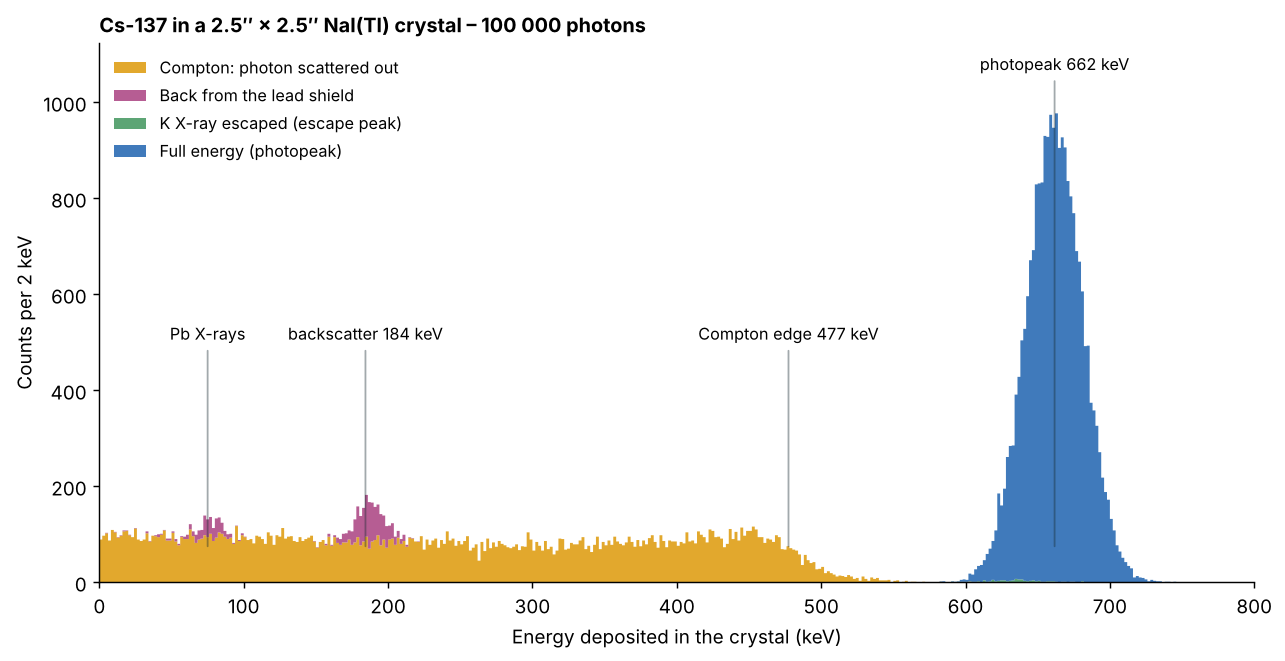

In [2]:
def plot_spectrum(r, ax=None, title=None, annotate=True, legend=True):
    """stacked histogram of a simulate() result"""
    ax = ax or plt.subplots(figsize=(10, 5.2), dpi=130)[1]
    x = np.linspace(0, r["emax"], r["bins"] + 1)
    base = np.zeros(r["bins"])
    for o in ("compton", "pair", "env", "escape", "photo"):
        h = np.array(r["hist"][o], float)
        if h.sum() == 0: continue
        ax.stairs(base + h, x, baseline=base, fill=True, color=COL[o], alpha=0.92, label=LAB[o])
        base += h
    ax.set_xlim(0, r["emax"]); ax.set_ylim(0, base.max() * 1.15)
    ax.set_xlabel("Energy deposited in the crystal (keV)"); ax.set_ylabel(f"Counts per {r['emax'] / r['bins']:.3g} keV")
    if title: ax.set_title(title, loc="left", weight="bold", fontsize=11)
    if legend: ax.legend(frameon=False, loc="upper left", fontsize=9)
    return ax

def stats(r):
    return {"emitted": r["n"], "interacted": r["interacted"], "full energy": r["peak"], "X-ray escape": sum(r["hist"]["escape"]),
            "full-energy share of interacting": round(r["peak"] / max(r["interacted"], 1), 3),
            "back from shield": sum(r["hist"]["env"])}

nai = pvmc.material("NaI(Tl)", XCOM)
setup = pvmc.Setup()          # 2.5" x 2.5", source at 2.2 cm, 1 mm Al, lead shield
fig2 = pvmc.simulate(nai, [(661.7, 1.0)], setup, n_photons=100_000, emax=800, bins=400, seed=42)
print(stats(fig2))

ax = plot_spectrum(fig2, title="Cs-137 in a 2.5″ × 2.5″ NaI(Tl) crystal – 100 000 photons")
E0 = 661.7
edge = E0 / (1 + 511 / (2 * E0)); back = E0 / (1 + 2 * E0 / 511)
for e, txt in [(E0, "photopeak 662 keV"), (edge, f"Compton edge {edge:.0f} keV"), (back, f"backscatter {back:.0f} keV"), (75, "Pb X-rays")]:
    ax.annotate(txt, (e, ax.get_ylim()[1] * 0.06), (e, ax.get_ylim()[1] * (0.95 if e == E0 else 0.45)),
                ha="center", fontsize=9, arrowprops=dict(arrowstyle="-", color="#172a31", alpha=0.4))
plt.tight_layout(); plt.savefig("figure2_cs137_nai.png", dpi=200); plt.show()

About half of the photons that interact leave their full energy; the rest form the Compton continuum up to the
Compton edge at 477 keV, plus the backscatter peak (≈ 184 keV) and lead X-rays (75–85 keV) from the shield.
The browser version on pvsensors.com gives the same result within the statistical scatter (50 %).

## 4. Your own crystal

Change the values below to your crystal and source. Example: a 10 × 10 × 5 mm³ CsPbBr₃ crystal with 1.0 % FWHM,
bare (no window), source 5 cm away, no shield.

{'emitted': 50000, 'interacted': 6248, 'full energy': 2087, 'X-ray escape': 210, 'full-energy share of interacting': 0.334, 'back from shield': 0}


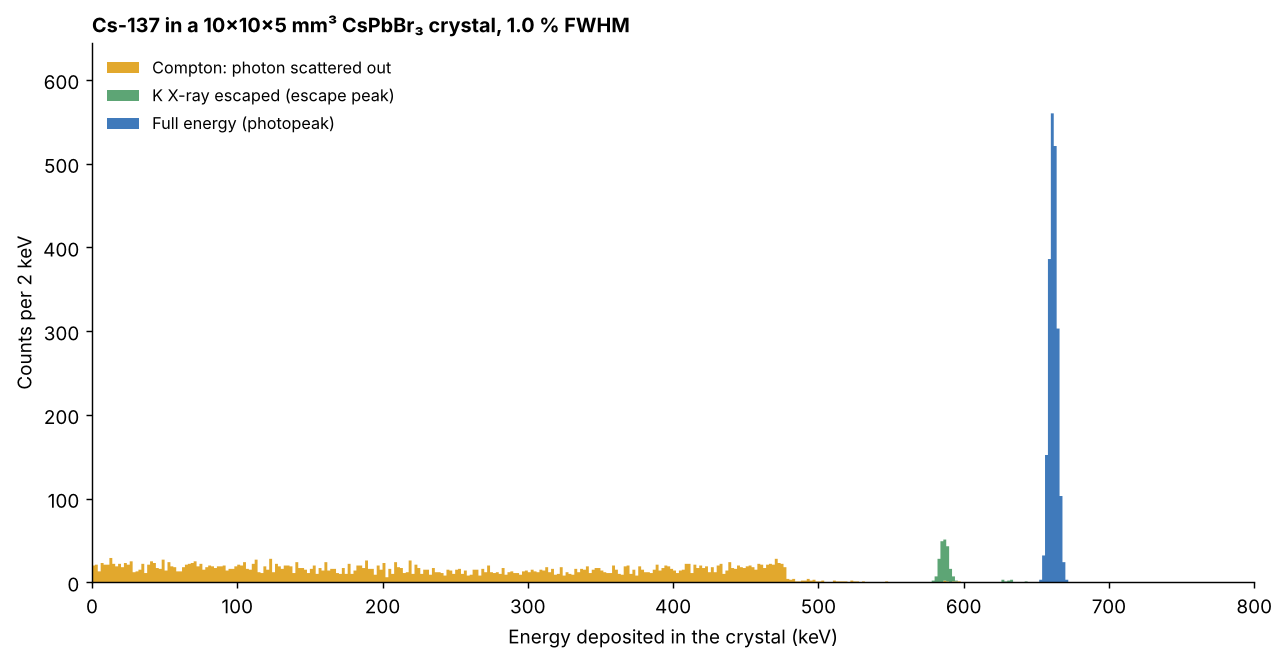

In [3]:
a_mm, b_mm, t_mm = 10, 10, 5                                  # your crystal (mm)
my = pvmc.material("CsPbBr3", XCOM, fwhm_662=1.0)            # your resolution at 662 keV
my_setup = pvmc.Setup(radius_cm=math.sqrt(a_mm * b_mm / math.pi) / 10, length_cm=t_mm / 10,
                      distance_cm=5.0, window_mm=0.0, shield=False)
r = pvmc.simulate(my, "Cs-137", my_setup, n_photons=50_000, emax=800, seed=1)
print(stats(r))
plot_spectrum(r, title=f"Cs-137 in a {a_mm}×{b_mm}×{t_mm} mm³ CsPbBr₃ crystal, 1.0 % FWHM")
plt.tight_layout(); plt.show()

A 5 mm crystal stops only a few per cent of 662 keV photons and most of those scatter out again, so the Compton
continuum is much larger than the photopeak – the reason why thick crystals matter for gamma spectroscopy.

## 5. All crystals, same source and size

Every crystal of the catalogue as a 1″ × 1″ cylinder (radius 1.27 cm, length 2.54 cm), ¹³⁷Cs at 2.2 cm, with shield.

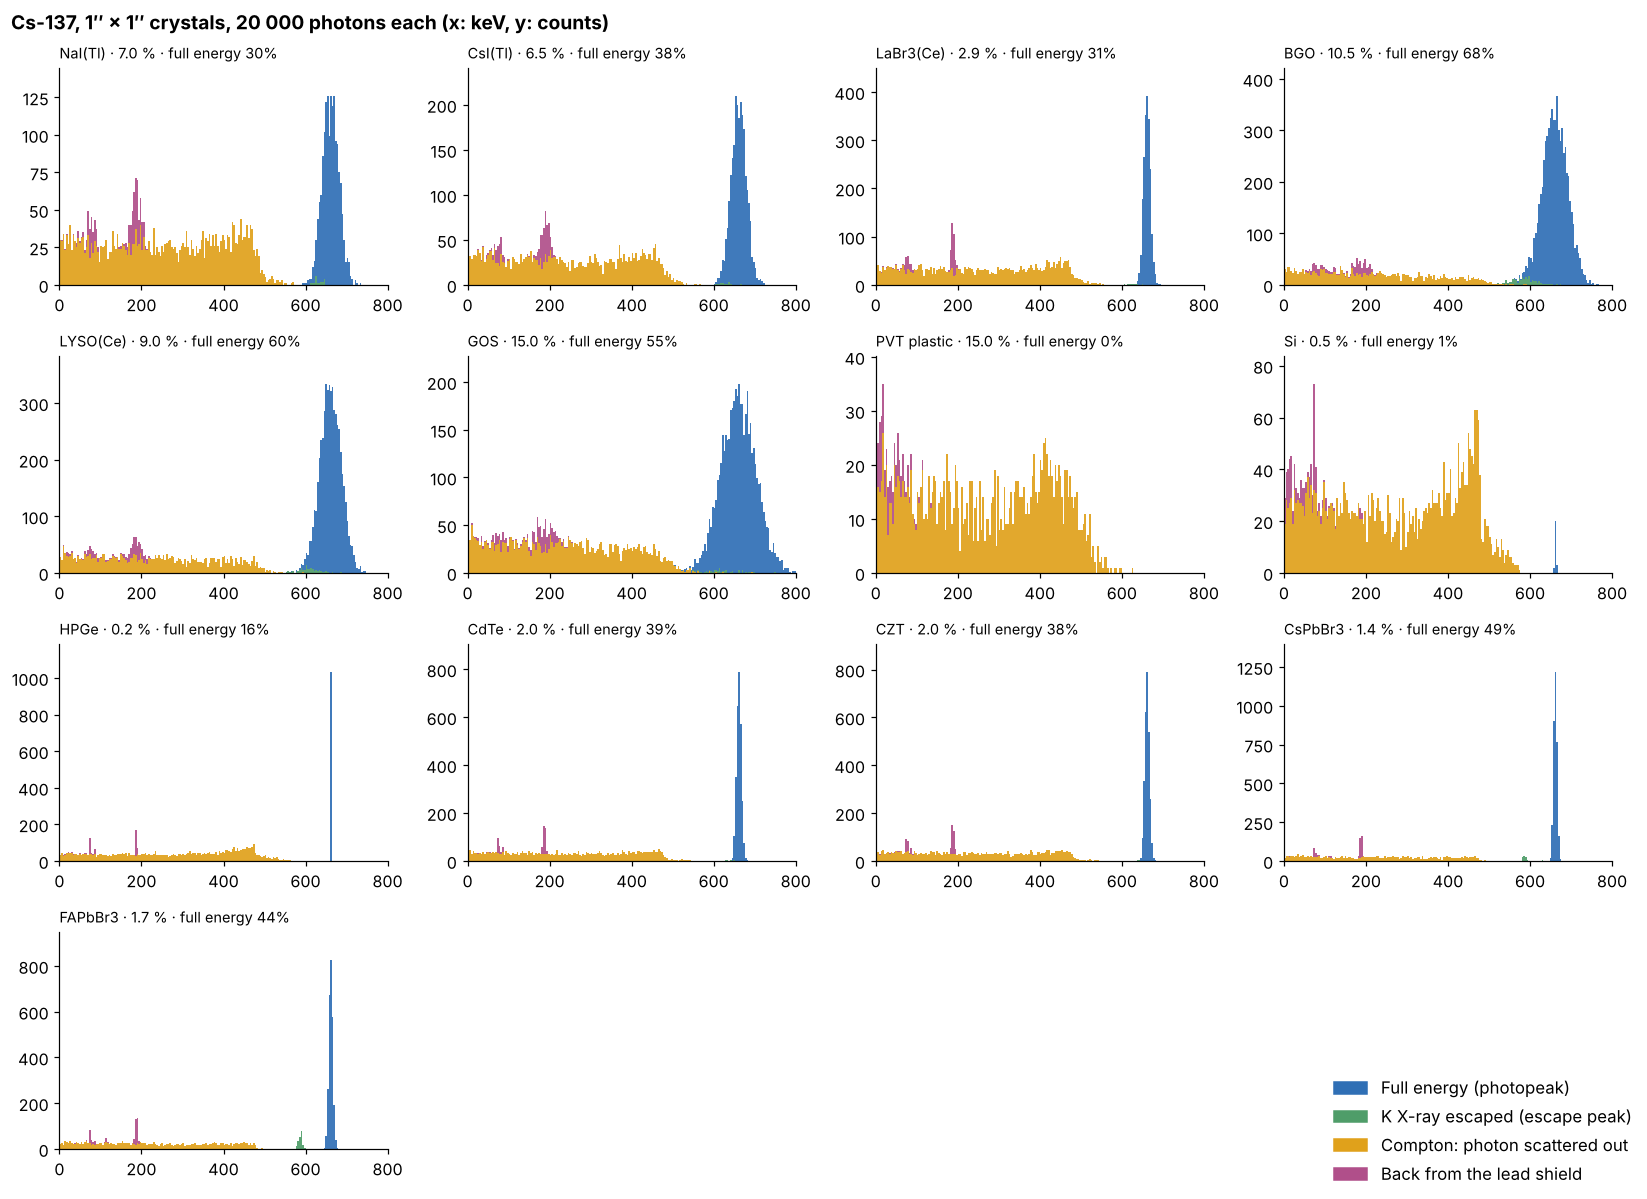

crystal      type          interacted  full energy  share
NaI(Tl)      scintillator        5377         1591    30%
CsI(Tl)      scintillator        6254         2352    38%
LaBr3(Ce)    scintillator        6583         2050    31%
BGO          scintillator        9452         6409    68%
LYSO(Ce)     scintillator        8850         5306    60%
GOS          scintillator        8814         4865    55%
PVT plastic  scintillator        1997            0     0%
Si           semiconductor       3714           25     1%
HPGe         semiconductor       6653         1035    16%
CdTe         semiconductor       7208         2816    39%
CZT          semiconductor       7176         2754    38%
CsPbBr3      semiconductor       6700         3309    49%
FAPbBr3      semiconductor       6007         2638    44%


In [4]:
size = pvmc.Setup(radius_cm=1.27, length_cm=2.54)
names = list(pvmc.CATALOGUE)
results = {n: pvmc.simulate(pvmc.material(n, XCOM), "Cs-137", size, n_photons=20_000, emax=800, bins=200, seed=7) for n in names}

fig, axes = plt.subplots(4, 4, figsize=(15, 11), dpi=110)
for ax, n in zip(axes.flat, names):
    plot_spectrum(results[n], ax=ax, legend=False)
    s = stats(results[n])
    ax.set_title(f"{n} · {pvmc.CATALOGUE[n]['fwhm_662']} % · full energy {s['full-energy share of interacting']:.0%}", fontsize=9.5, loc="left")
    ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[len(names):]: ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[o]) for o in ("photo", "escape", "compton", "env")]
fig.legend(handles, [LAB[o] for o in ("photo", "escape", "compton", "env")], loc="lower right", frameon=False, fontsize=11)
fig.suptitle("Cs-137, 1″ × 1″ crystals, 20 000 photons each (x: keV, y: counts)", x=0.01, ha="left", weight="bold")
plt.tight_layout(); plt.savefig("all_crystals_cs137.png", dpi=150); plt.show()

print(f"{'crystal':12s} {'type':13s} {'interacted':>10s} {'full energy':>12s} {'share':>6s}")
for n in names:
    s = stats(results[n]); k = pvmc.CATALOGUE[n]["kind"]
    print(f"{n:12s} {k:13s} {s['interacted']:10d} {s['full energy']:12d} {s['full-energy share of interacting']:6.0%}")

Dense, high-Z crystals (BGO, LYSO, CsPbBr₃, CdTe/CZT) keep more photons in the photopeak than NaI(Tl) of the same
size; germanium and silicon, with lower Z, lose more to Compton scattering; plastic (Z ≈ 6) shows no photopeak at all.
Resolution decides how sharp the peak is (HPGe and the semiconductors vs the scintillators).

## 6. Different sources in one crystal

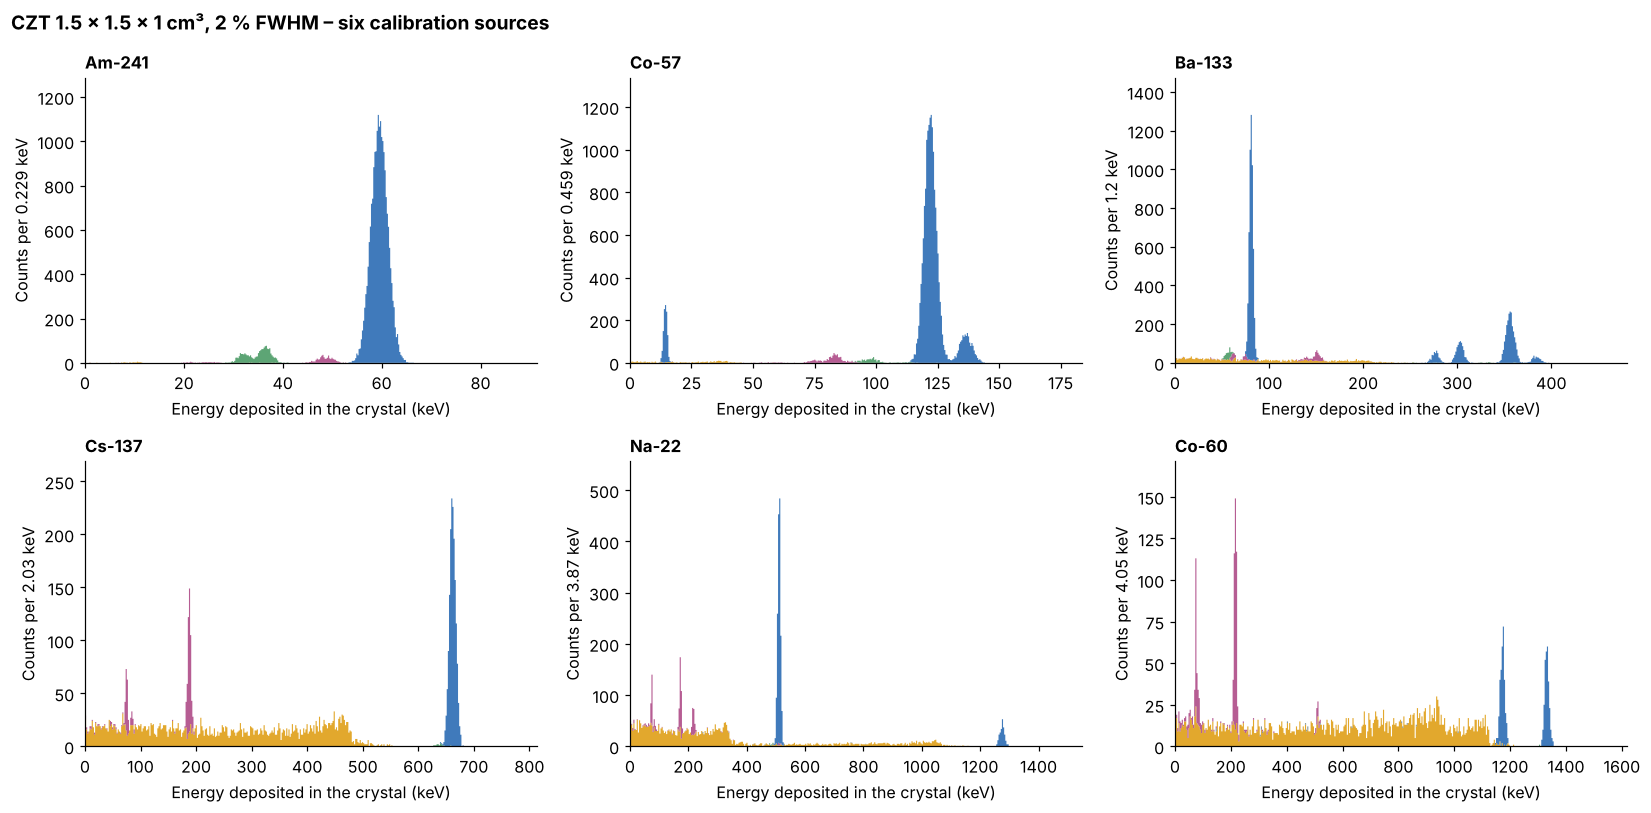

In [5]:
crystal = pvmc.material("CZT", XCOM, fwhm_662=2.0)
geom = pvmc.Setup(radius_cm=0.85, length_cm=1.0, window_mm=0.2)      # ~ 1.5 cm × 1.5 cm × 1 cm CZT
srcs = ["Am-241", "Co-57", "Ba-133", "Cs-137", "Na-22", "Co-60"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), dpi=110)
for ax, s in zip(axes.flat, srcs):
    r = pvmc.simulate(crystal, s, geom, n_photons=30_000, seed=3)
    plot_spectrum(r, ax=ax, legend=False, title=s)
fig.suptitle("CZT 1.5 × 1.5 × 1 cm³, 2 % FWHM – six calibration sources", x=0.01, ha="left", weight="bold")
plt.tight_layout(); plt.savefig("czt_sources.png", dpi=150); plt.show()

Note the Cd/Te K X-ray escape peaks (green) about 23–27 keV below the 59.5 keV and 122 keV lines, the 511 keV annihilation
line of ²²Na, and – for ⁶⁰Co and ²²Na – single and double escape peaks are tiny in such a small crystal.
(True coincidence summing of the two ⁶⁰Co gammas is not simulated.)

## 7. Full-energy-peak efficiency versus energy

With `sampling="cone"` the photons are emitted isotropically, so `peak / n × solid-angle fraction` is the absolute
full-energy-peak efficiency of the setup (what you need to turn counts into becquerels).

/tmp/ipykernel_346/1552363292.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.plot(energies, np.array(eff) * 100, "o-", color=c, lw=2, ms=5, ls="--" if n == "HPGe" else "-", label=n)


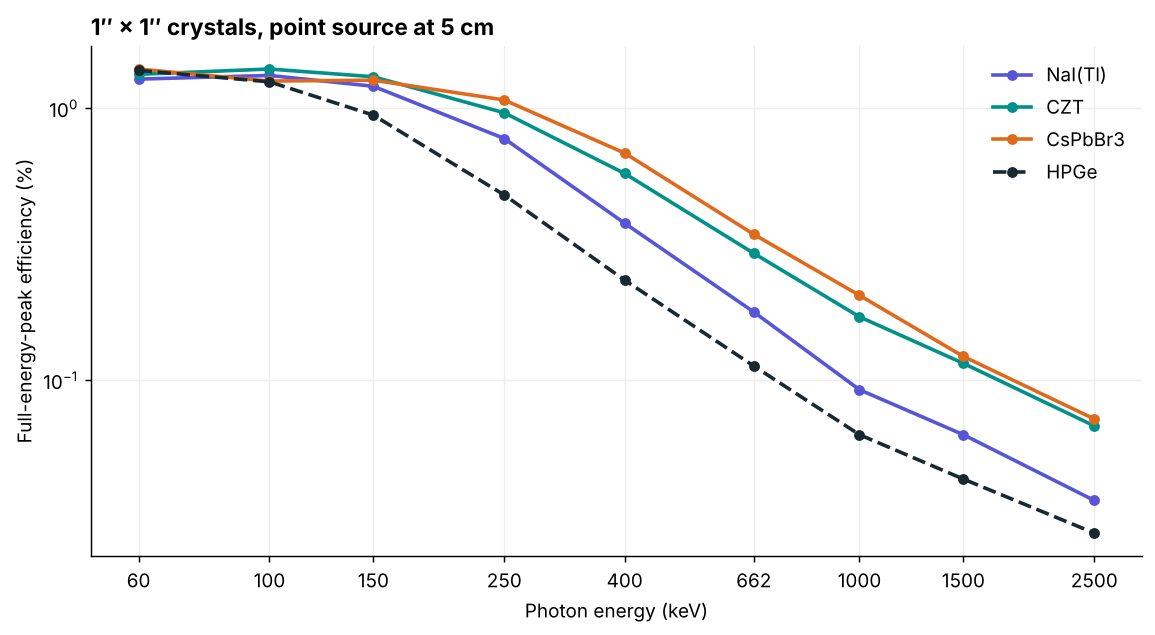

In [6]:
energies = [60, 100, 150, 250, 400, 662, 1000, 1500, 2500]
crystals = {"NaI(Tl)": "#5856d6", "CZT": "#00918a", "CsPbBr3": "#e06a1b", "HPGe": "#172a31"}
geo = pvmc.Setup(radius_cm=1.27, length_cm=2.54, distance_cm=5.0, shield=False, sampling="cone")
frac = (1 - geo.distance_cm / math.hypot(geo.distance_cm, geo.radius_cm)) / 2     # share of 4π inside the cone
fig, ax = plt.subplots(figsize=(9, 5), dpi=130)
for n, c in crystals.items():
    m = pvmc.material(n, XCOM)
    eff = [pvmc.simulate(m, e, geo, n_photons=6000, seed=11)["peak"] / 6000 * frac for e in energies]
    ax.plot(energies, np.array(eff) * 100, "o-", color=c, lw=2, ms=5, ls="--" if n == "HPGe" else "-", label=n)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(energies); ax.set_xticklabels([str(e) for e in energies]); ax.minorticks_off()
ax.set_xlabel("Photon energy (keV)"); ax.set_ylabel("Full-energy-peak efficiency (%)")
ax.set_title("1″ × 1″ crystals, point source at 5 cm", loc="left", weight="bold")
ax.legend(frameon=False); ax.grid(True, which="both", color="#eceeea")
plt.tight_layout(); plt.savefig("efficiency_vs_energy.png", dpi=150); plt.show()

## 8. Save a spectrum

In [7]:
def save_csv(r, path):
    x = np.linspace(0, r["emax"], r["bins"] + 1)
    centers = (x[:-1] + x[1:]) / 2
    cols = np.column_stack([centers] + [r["hist"][o] for o in pvmc.OUTCOMES])
    np.savetxt(path, cols, delimiter=",", fmt=["%.3f"] + ["%d"] * len(pvmc.OUTCOMES),
               header="energy_keV," + ",".join(pvmc.OUTCOMES), comments="")
    print("saved", path)

save_csv(fig2, "figure2_cs137_nai.csv")

saved figure2_cs137_nai.csv


---
**Data:** M. J. Berger, J. H. Hubbell, S. M. Seltzer *et al.*, *XCOM: Photon Cross Sections Database*,
NIST Standard Reference Database 8, [doi:10.18434/T48G6X](https://doi.org/10.18434/T48G6X).
**Physics:** O. Klein, Y. Nishina, *Z. Phys.* **52**, 853 (1929); G. F. Knoll, *Radiation Detection and Measurement*,
4th ed. (Wiley, 2010), ch. 2 and 10; G. R. Gilmore, *Practical Gamma-ray Spectrometry*, 2nd ed. (Wiley, 2008), ch. 2.
© PV Sensors – <https://pvsensors.com>